# Dance floor contact · master notebook

**Team walkthrough, 11 November 2026.** The project maps dancers from the source video onto a top-down floor view. This package covers the fixed-camera section through the 0.30 display replay. Use the [research notebook](Research_Notebook.ipynb) for the measurements, annotation audit, and experiment outputs.

Run all cells from the project folder. The notebook reads packaged artifacts and needs no GPU.

In [1]:
from pathlib import Path
import json
from IPython.display import Image, Video, display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "tools/run_notebooks.py").is_file())
TRIAL = ROOT / "Experiment/lighting_expansion_200"
REVISION = TRIAL / "visual_relabel"
RUN = TRIAL / "runs/lighting_200_visual_s17"
DEMO = RUN / "display_threshold_0.3"

def load(path):
    return json.loads(path.read_text(encoding="utf-8"))

def show_replay():
    display(Image(filename=str(DEMO / "replay_preview.jpg"), width=950))
    display(Video(url=(DEMO / "lighting_trial_replay.mp4").relative_to(ROOT).as_posix(), width=950))

## 1. Pick the section and define the output

The usable static-camera section is source frames 3250–5673, inclusive. A fixed homography projects contact points from that camera angle onto the mat. The video preview shows the image and map together so a viewer can check where dots land. Moving-camera footage would need a separate calibration.

In [2]:
sweep = load(RUN / "display_sweep.json")
frames = sweep[-1]["frames"]
print(f"{frames:,} frames at 25 fps, {frames / 25:.2f} seconds")
print("Pipeline: dancer boxes → track IDs → support and visibility → floor projection → offline trajectory fit")

2,424 frames at 25 fps, 96.96 seconds
Pipeline: dancer boxes → track IDs → support and visibility → floor projection → offline trajectory fit


## 2. Detect dancers and keep identities

YOLO supplies the dancer boxes. Tracking links boxes across frames so a dot can follow one dancer. Dense overlaps caused gaps and identity switches. A detector trained with more brightness variation gave a small development gain in correct IDs. We reused the published detections and tracks for the 200-frame support trial so the comparison would isolate the support stage.

## 3. Find the point that belongs on the floor

The bottom center of a box was a useful first proxy for standing poses. It failed when dancers knelt, sat, used their palms, jumped, or overlapped. A separate image-based head predicts where the body bears weight and whether that contact can be reported. The offline fit reduces sudden map changes and fills short gaps with marked estimates. It uses future frames, so the replay is an offline result.

## 4. Expand and revise the labels

We added 140 lighting- and time-diverse images to the original 60 training images, then revised all 200. Consecutive frames often look alike. Sampling across lighting changes and choreography gave the labeling effort more variety. The first prelabels missed lower box edges and confused floor-level poses. The visual revision checked full visible body extents and actual supporting feet, knees, seat, or palms. It restored the floor guides used for calibration context.

The revised labels are approximate assistant estimates. Four contacts remain uncertain and were excluded from training crops. The CVAT round trip checked the transfer of all labels and floor guides.

In [3]:
audit = load(REVISION / "cvat_roundtrip_check.json")
print(f"CVAT transfer {audit['status']}: {audit['frames']} images, {audit['dancer_boxes']:,} boxes, "
      f"{audit['support_points']:,} support points, {audit['floor_polylines']:,} floor guides")
print(audit["task_url"])

CVAT transfer passed: 200 images, 3,689 boxes, 3,017 support points, 2,400 floor guides
https://app.cvat.ai/tasks/2754547/jobs/4717612


## 5. Train and compare on the reserved frames

The fresh support model trained for 30 epochs on BESTIJA's RTX 5080. The original 11 validation frames were used to select the model and its 0.90 scoring threshold. The replay uses epoch 3, selected by validation joint F1. Training continued to epoch 30, but validation loss rose and the late model was not selected.

The 200-image trial reported fewer hidden contacts as measured, but localized fewer visible contacts within 3% of mat width. Keep the published baseline as the established accuracy result. The comparison uses seven reserved images from the same choreography.

In [4]:
comparison = load(RUN / "evaluation/results.json")
for key, title in [("baseline", "Published baseline"), ("candidate", "200-image revision")]:
    result = comparison[key]["all"]
    print(f"{title}: {result['correct_by_tolerance_pct_width']['3']}/{result['visible_references']} within 3%; "
          f"{result['hidden_measured']}/{result['hidden_references']} hidden contacts reported as measured")

Published baseline: 29/46 within 3%; 5/50 hidden contacts reported as measured
200-image revision: 26/46 within 3%; 3/50 hidden contacts reported as measured


## 6. Review the 0.30 map replay

The display sweep lowered the support threshold and refit the trajectories with the same dancer tracks. Lowering 0.40 to 0.30 added 903 displayed dots. Single-frame flicker stayed at nine, and the measured size of abrupt movement changes stayed nearly identical. Solid dots are reported contacts. Hollow dots are estimated positions. The replay includes training frames and was reviewed for display coverage and motion.

0.40: 34,693 dots, 14.3 per frame, 9 flickers
0.30: 35,596 dots, 14.7 per frame, 9 flickers


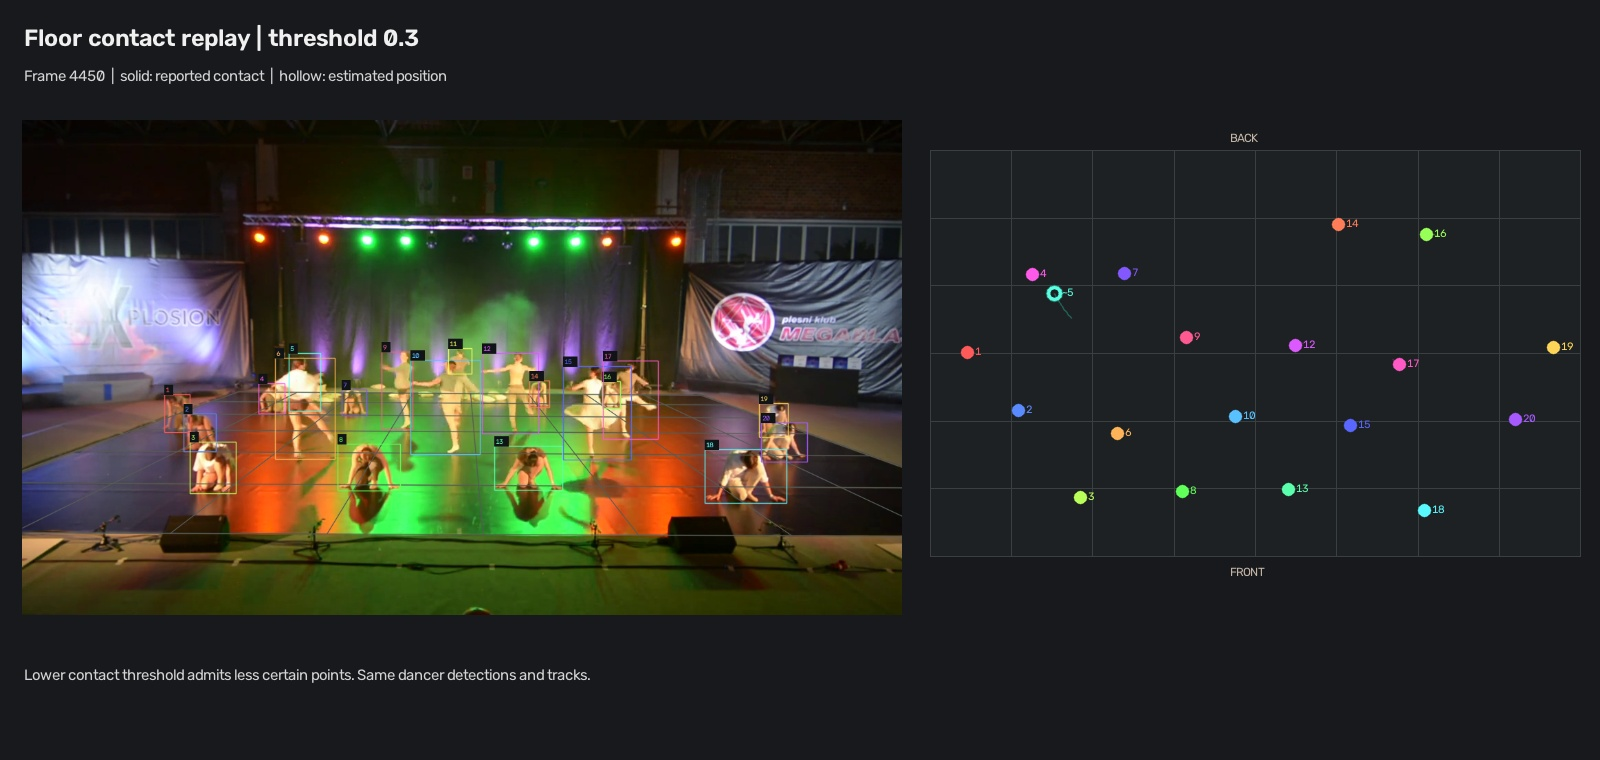

In [5]:
for row in sweep[-2:]:
    print(f"{row['threshold']:.2f}: {row['displayed_dots']:,} dots, "
          f"{row['displayed_dots'] / frames:.1f} per frame, {row['single_frame_flickers']} flickers")
show_replay()

## 7. Handoff for the team call

Play the 0.30 replay, show a before-and-after CVAT example in the research notebook, and explain the difference between the frozen accuracy result and the denser display. The pending project step is detecting formations on the map. The [per-frame map export](Experiment/lighting_expansion_200/runs/lighting_200_visual_s17/display_threshold_0.3/map_positions.json) includes track IDs, floor coordinates, and contact or estimate status so the team can inspect the inputs together.